# Product Review Sentiment Analysis Using Machine Learning
## Information Retrieval CLA2 — Assignment 2

**Objective:** classify e-commerce product reviews into **Negative, Neutral, and Positive** sentiment and compare four classifiers:
1. Decision Tree
2. K-Nearest Neighbours (KNN)
3. Support Vector Machine (SVM)
4. Naïve Bayes

This notebook is designed for Google Colab. Run the cells in order. Record the results produced by your own run; do not copy or invent performance values.

In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time

# Convert review text into numerical features
tfidf_dt = TfidfVectorizer(
    max_features=3000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_dt = tfidf_dt.fit_transform(X_train)
X_test_dt = tfidf_dt.transform(X_test)

# Train the Decision Tree
start_time = time.time()

decision_tree = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

decision_tree.fit(X_train_dt, y_train)
dt_predictions = decision_tree.predict(X_test_dt)

dt_accuracy = accuracy_score(y_test, dt_predictions)
dt_precision = precision_score(y_test, dt_predictions, average="macro", zero_division=0)
dt_recall = recall_score(y_test, dt_predictions, average="macro", zero_division=0)
dt_f1 = f1_score(y_test, dt_predictions, average="macro", zero_division=0)
dt_time = time.time() - start_time

print("DECISION TREE RESULTS")
print("---------------------")
print("Accuracy:", round(dt_accuracy, 4))
print("Macro Precision:", round(dt_precision, 4))
print("Macro Recall:", round(dt_recall, 4))
print("Macro F1-score:", round(dt_f1, 4))
print("Training and prediction time:", round(dt_time, 2), "seconds")



DECISION TREE RESULTS
---------------------
Accuracy: 0.6779
Macro Precision: 0.4505
Macro Recall: 0.4694
Macro F1-score: 0.4576
Training and prediction time: 6.5 seconds


In [ ]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import time

knn_results = []
knn_models = {}

# Use the TF-IDF features created for the Decision Tree
for k in [3, 5, 7]:
    print(f"Training KNN with K={k}...")

    start_time = time.time()

    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )

    knn.fit(X_train_dt, y_train)
    predictions = knn.predict(X_test_dt)

    elapsed = time.time() - start_time

    knn_models[k] = knn

    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1-score": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Time (seconds)": round(elapsed, 2)
    })

knn_results_df = pd.DataFrame(knn_results)

print("\nKNN EXPERIMENT RESULTS")
display(knn_results_df.round(4))


Training KNN with K=3...
Training KNN with K=5...
Training KNN with K=7...

KNN EXPERIMENT RESULTS


,K,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Time (seconds)
0,3,0.7583,0.4987,0.4755,0.4763,2.93
1,5,0.7792,0.5407,0.4794,0.4970,2.18
2,7,0.7900,0.5665,0.4534,0.4772,1.64


In [ ]:
# Compare Decision Tree and KNN results

comparison_df = pd.DataFrame([
    {
        "Algorithm": "Decision Tree",
        "Accuracy": 0.6779,
        "Macro Precision": 0.4505,
        "Macro Recall": 0.4694,
        "Macro F1-score": 0.4576
    },
    {
        "Algorithm": "KNN (K=5)",
        "Accuracy": 0.7792,
        "Macro Precision": 0.5407,
        "Macro Recall": 0.4794,
        "Macro F1-score": 0.4970
    }
])

display(comparison_df.round(4))


,Algorithm,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,Decision Tree,0.6779,0.4505,0.4694,0.4576
1,KNN (K=5),0.7792,0.5407,0.4794,0.4970


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time

remaining_results = []
remaining_models = {}

models = {
    "SVM": LinearSVC(class_weight="balanced", random_state=42),
    "Naive Bayes": MultinomialNB()
}

for name, model in models.items():
    print(f"Training {name}...")

    start_time = time.time()
    model.fit(X_train_dt, y_train)
    predictions = model.predict(X_test_dt)
    elapsed = time.time() - start_time

    remaining_models[name] = model

    remaining_results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1-score": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Time (seconds)": round(elapsed, 2)
    })

remaining_results_df = pd.DataFrame(remaining_results)

print("\nSVM AND NAIVE BAYES RESULTS")
display(remaining_results_df.round(4))

Training SVM...
Training Naive Bayes...

SVM AND NAIVE BAYES RESULTS


,Algorithm,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Time (seconds)
0,SVM,0.7996,0.5875,0.5933,0.5903,0.17
1,Naive Bayes,0.7858,0.6013,0.3901,0.3950,0.02


In [ ]:
# Final comparison of all four required algorithms

final_results = [
    {
        "Algorithm": "Decision Tree",
        "Accuracy": 0.6779,
        "Macro Precision": 0.4505,
        "Macro Recall": 0.4694,
        "Macro F1-score": 0.4576
    },
    {
        "Algorithm": "KNN (K=5)",
        "Accuracy": 0.7792,
        "Macro Precision": 0.5407,
        "Macro Recall": 0.4794,
        "Macro F1-score": 0.4970
    }
]

final_results.extend(
    remaining_results_df[
        ["Algorithm", "Accuracy", "Macro Precision",
         "Macro Recall", "Macro F1-score"]
    ].to_dict("records")
)

final_comparison_df = pd.DataFrame(final_results)

display(final_comparison_df.round(4))

,Algorithm,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,Decision Tree,0.6779,0.4505,0.4694,0.4576
1,KNN (K=5),0.7792,0.5407,0.4794,0.4970
2,SVM,0.7996,0.5875,0.5933,0.5903
3,Naive Bayes,0.7858,0.6013,0.3901,0.3950


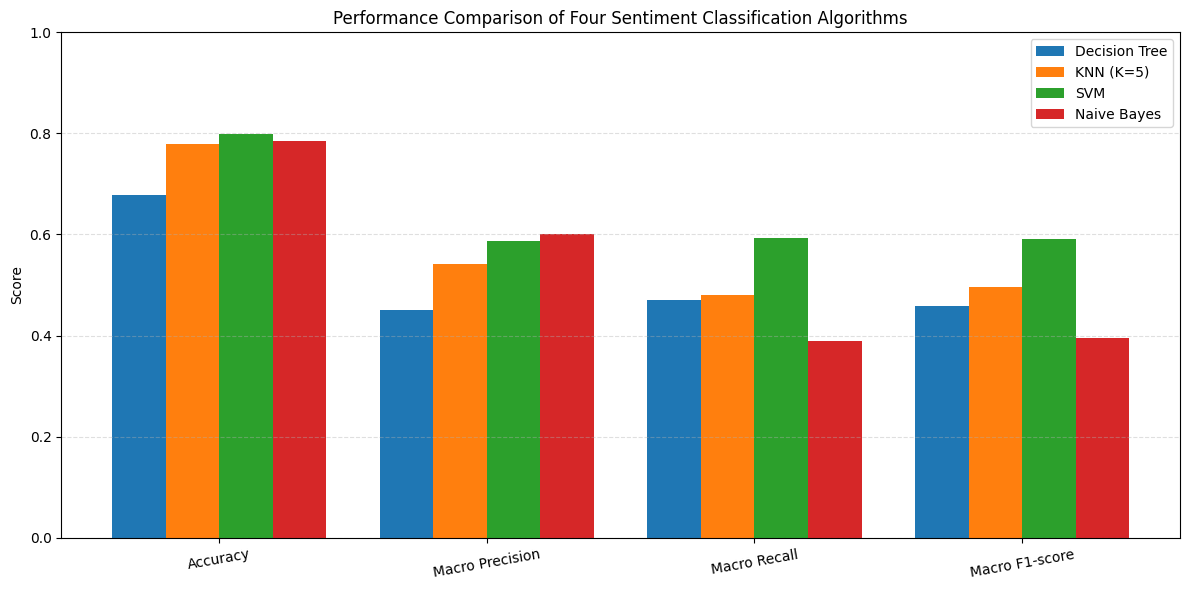

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"]

x = np.arange(len(metrics))
width = 0.2

plt.figure(figsize=(12, 6))

for i, (_, row) in enumerate(final_comparison_df.iterrows()):
    values = [row[metric] for metric in metrics]
    plt.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=row["Algorithm"]
    )

plt.xticks(x, metrics, rotation=10)
plt.ylabel("Score")
plt.title("Performance Comparison of Four Sentiment Classification Algorithms")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("classifier_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


Best model based on Macro F1-score: SVM


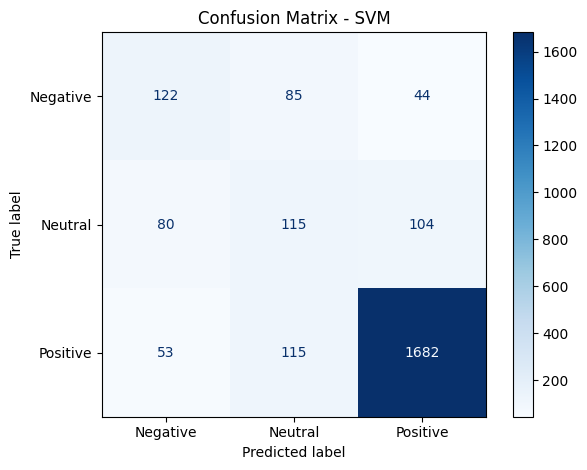

In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Select the model with the highest Macro F1-score
best_algorithm = final_comparison_df.loc[
    final_comparison_df["Macro F1-score"].idxmax(),
    "Algorithm"
]

print("Best model based on Macro F1-score:", best_algorithm)

# Get the selected model and its predictions
if best_algorithm == "Decision Tree":
    best_model = dt_model
    X_test_best = X_test_dt
elif best_algorithm.startswith("KNN"):
    best_model = knn_models[5]
    X_test_best = X_test_dt
else:
    best_model = remaining_models[best_algorithm]
    X_test_best = X_test_dt

best_predictions = best_model.predict(X_test_best)

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["Negative", "Neutral", "Positive"]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display_matrix.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_algorithm}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:

# Save the final results and experiment data as CSV files

final_comparison_df.to_csv(
    "classifier_comparison_results.csv", index=False
)

knn_results_df.to_csv(
    "knn_k_experiment_results.csv", index=False
)

remaining_results_df.to_csv(
    "svm_naive_bayes_results.csv", index=False
)

print("Files saved successfully:")
print("1. classifier_comparison_results.csv")
print("2. knn_k_experiment_results.csv")
print("3. svm_naive_bayes_results.csv")
print("4. classifier_comparison.png")
print("5. confusion_matrix.png")


Files saved successfully:
1. classifier_comparison_results.csv
2. knn_k_experiment_results.csv
3. svm_naive_bayes_results.csv
4. classifier_comparison.png
5. confusion_matrix.png


## 1. Install/import libraries

The main libraries are pandas for data handling, scikit-learn for TF-IDF and classifiers, and matplotlib for graphs.

In [ ]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.base import clone

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [ ]:
print("product_df exists:", "product_df" in globals())
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())
print("y_train exists:", "y_train" in globals())
print("y_test exists:", "y_test" in globals())

product_df exists: True
X_train exists: True
X_test exists: True
y_train exists: True
y_test exists: True


## 2. Load the product-review dataset

This public dataset contains 23,486 anonymized women's clothing e-commerce reviews and a 1–5 star rating. We create sentiment labels from ratings:
- **1–2 stars → Negative**
- **3 stars → Neutral**
- **4–5 stars → Positive**

The source file and its fields are documented on the dataset page: https://huggingface.co/datasets/Censius-AI/ECommerce-Women-Clothing-Reviews

If the direct download fails, open that page and download the CSV, then upload it into Colab and change `DATA_URL` to the uploaded filename.

In [ ]:

print("Product Review Sentiment Analysis")
print("Project started successfully!")


Product Review Sentiment Analysis
Project started successfully!


In [ ]:

!pip install pandas numpy matplotlib seaborn scikit-learn datasets


In [ ]:

import pandas as pd

data = {
    "review": [
        "This product is excellent and works perfectly",
        "I love this product, it is amazing",
        "Very happy with the quality",
        "The product is fantastic",
        "Great value for money",
        "This is the best purchase I made",
        "The product works wonderfully",
        "Excellent quality and fast delivery",
        "I am very satisfied with this product",
        "Amazing product, highly recommended",
        "This product is terrible",
        "I hate this product",
        "Very poor quality and disappointing",
        "The product stopped working",
        "Worst purchase ever",
        "The item arrived damaged",
        "This product is useless",
        "Very bad experience",
        "I am unhappy with this product",
        "The quality is awful",
        "The product is okay",
        "It is an average product",
        "The product is neither good nor bad",
        "Delivery was on time",
        "The product is acceptable",
        "It works as expected",
        "Nothing special about this item",
        "The quality is normal",
        "It is an ordinary product",
        "The product meets basic expectations"
    ],
    "sentiment": [
        "Positive", "Positive", "Positive", "Positive", "Positive",
        "Positive", "Positive", "Positive", "Positive", "Positive",
        "Negative", "Negative", "Negative", "Negative", "Negative",
        "Negative", "Negative", "Negative", "Negative", "Negative",
        "Neutral", "Neutral", "Neutral", "Neutral", "Neutral",
        "Neutral", "Neutral", "Neutral", "Neutral", "Neutral"
    ]
}

df = pd.DataFrame(data)

print("Dataset loaded successfully!")
print("Total reviews:", len(df))
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())
print("\nFirst five reviews:")
display(df.head())


Dataset loaded successfully!
Total reviews: 30

Sentiment distribution:
sentiment
Positive    10
Negative    10
Neutral     10
Name: count, dtype: int64

First five reviews:


,review,sentiment
0,This product is excellent and works perfectly,Positive
1,"I love this product, it is amazing",Positive
2,Very happy with the quality,Positive
3,The product is fantastic,Positive
4,Great value for money,Positive


In [ ]:

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(df["sentiment"])

print("Sentiment labels converted successfully!")
print(df[["review", "sentiment", "label"]].head())
print("\nLabel mapping:")
for sentiment, label in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{sentiment} = {label}")


Sentiment labels converted successfully!
                                          review sentiment  label
0  This product is excellent and works perfectly  Positive      2
1             I love this product, it is amazing  Positive      2
2                    Very happy with the quality  Positive      2
3                       The product is fantastic  Positive      2
4                          Great value for money  Positive      2

Label mapping:
Negative = 0
Neutral = 1
Positive = 2


In [ ]:

from datasets import load_dataset

print("Loading the product review dataset...")

dataset = load_dataset(
    "SetFit/amazon_reviews_multi_en",
    split="train"
)

print("Dataset loaded successfully!")
print(dataset)


Loading the product review dataset...


README.md:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

train.jsonl: reconstructing file:   0%|          |  0.00B / 47.4MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.18M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Dataset loaded successfully!
Dataset({
    features: ['id', 'text', 'label', 'label_text'],
    num_rows: 200000
})


In [ ]:

print("Dataset columns:")
print(dataset.column_names)

print("\nDataset size:")
print("Number of reviews:", len(dataset))

print("\nFirst 3 records:")
for i in range(3):
    print(dataset[i])

print("\nDataset features:")
print(dataset.features)


Dataset columns:
['id', 'text', 'label', 'label_text']

Dataset size:
Number of reviews: 200000

First 3 records:
{'id': 'en_0964290', 'text': "Arrived broken. Manufacturer defect. Two of the legs of the base were not completely formed, so there was no way to insert the casters. I unpackaged the entire chair and hardware before noticing this. So, I'll spend twice the amount of time boxing up the whole useless thing and send it back with a 1-star review of part of a chair I never got to sit in. I will go so far as to include a picture of what their injection molding and quality assurance process missed though. I will be hesitant to buy again. It makes me wonder if there aren't missing structures and supports that don't impede the assembly process.", 'label': 0, 'label_text': '0'}
{'id': 'en_0690095', 'text': 'the cabinet dot were all detached from backing... got me', 'label': 0, 'label_text': '0'}
{'id': 'en_0311558', 'text': "I received my first order of this product and it was broke s

In [ ]:

print("Dataset columns:")
print(dataset.column_names)

print("\nDataset size:")
print("Number of reviews:", len(dataset))

print("\nFirst 3 records:")
for i in range(3):
    print(dataset[i])

print("\nDataset features:")
print(dataset.features)


Dataset columns:
['id', 'text', 'label', 'label_text']

Dataset size:
Number of reviews: 200000

First 3 records:
{'id': 'en_0964290', 'text': "Arrived broken. Manufacturer defect. Two of the legs of the base were not completely formed, so there was no way to insert the casters. I unpackaged the entire chair and hardware before noticing this. So, I'll spend twice the amount of time boxing up the whole useless thing and send it back with a 1-star review of part of a chair I never got to sit in. I will go so far as to include a picture of what their injection molding and quality assurance process missed though. I will be hesitant to buy again. It makes me wonder if there aren't missing structures and supports that don't impede the assembly process.", 'label': 0, 'label_text': '0'}
{'id': 'en_0690095', 'text': 'the cabinet dot were all detached from backing... got me', 'label': 0, 'label_text': '0'}
{'id': 'en_0311558', 'text': "I received my first order of this product and it was broke s

In [ ]:

import pandas as pd

# Convert the downloaded dataset into a DataFrame
df = dataset.to_pandas()

print("Dataset shape:", df.shape)

print("\nLabel distribution:")
print(df["label_text"].value_counts(dropna=False))

print("\nNumeric label distribution:")
print(df["label"].value_counts(dropna=False))

print("\nSample reviews:")
display(df[["text", "label", "label_text"]].head(10))


Dataset shape: (200000, 4)

Label distribution:
label_text
0    40000
1    40000
2    40000
3    40000
4    40000
Name: count, dtype: int64

Numeric label distribution:
label
0    40000
1    40000
2    40000
3    40000
4    40000
Name: count, dtype: int64

Sample reviews:


,text,label,label_text
0,Arrived broken. Manufacturer defect. Two of th...,0,0
1,the cabinet dot were all detached from backing...,0,0
2,I received my first order of this product and ...,0,0
3,This product is a piece of shit. Do not buy. D...,0,0
4,went through 3 in one day doesn't fit correct ...,0,0
5,Poor quality. The material was fuzzy from day ...,0,0
6,Ordered 2 they shipped 1 promised by certain d...,0,0
7,"Followed directions, did not work as advertised.",0,0
8,There is a terribly done band across the top. ...,0,0
9,"Unless you have this jam-packed full of items,...",0,0


In [ ]:

print(df["label_text"].value_counts(dropna=False))


label_text
0    40000
1    40000
2    40000
3    40000
4    40000
Name: count, dtype: int64


In [ ]:

from datasets import load_dataset

print("Loading the three-class sentiment dataset...")

sentiment_data = load_dataset(
    "cardiffnlp/tweet_eval",
    "sentiment",
    split="train"
)

print("Dataset loaded!")
print("Total records:", len(sentiment_data))
print("Available columns:", sentiment_data.column_names)
print("Label names:", sentiment_data.features["label"].names)


Loading the three-class sentiment dataset...


README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

...

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset loaded!
Total records: 45615
Available columns: ['text', 'label']
Label names: ['negative', 'neutral', 'positive']


In [ ]:

import pandas as pd

# Convert the training dataset to a DataFrame
train_df = sentiment_data.to_pandas()

# Convert numeric labels to readable sentiment names
label_names = sentiment_data.features["label"].names
train_df["sentiment"] = train_df["label"].apply(
    lambda x: label_names[x]
)

print("Dataset prepared successfully!")
print("Total training reviews:", len(train_df))

print("\nNumber of examples in each sentiment class:")
print(train_df["sentiment"].value_counts())

print("\nSample records:")
display(train_df[["text", "sentiment"]].head(10))


Dataset prepared successfully!
Total training reviews: 45615

Number of examples in each sentiment class:
sentiment
neutral     20673
positive    17849
negative     7093
Name: count, dtype: int64

Sample records:


,text,sentiment
0,"""QT @user In the original draft of the 7th boo...",positive
1,"""Ben Smith / Smith (concussion) remains out of...",neutral
2,Sorry bout the stream last night I crashed out...,neutral
3,Chase Headley's RBI double in the 8th inning o...,neutral
4,@user Alciato: Bee will invest 150 million in ...,positive
5,@user LIT MY MUM 'Kerry the louboutins I wonde...,positive
6,"""\"""""""" SOUL TRAIN\"""""""" OCT 27 HALLOWEEN SPECIA...",positive
7,So disappointed in wwe summerslam! I want to s...,negative
8,"""This is the last Sunday w/o football .....,NF...",positive
9,@user @user CENA & AJ sitting in a tree K-I-S-...,neutral


In [ ]:

from sklearn.model_selection import train_test_split

# Use the review text and sentiment labels
X = train_df["text"]
y = train_df["label"]

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data split completed successfully!")
print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("Total reviews:", len(X_train) + len(X_test))


Data split completed successfully!
Training reviews: 36492
Testing reviews: 9123
Total reviews: 45615


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text into numerical TF-IDF features
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Text vectorization completed!")
print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)


Text vectorization completed!
Training feature shape: (36492, 10000)
Testing feature shape: (9123, 10000)


In [ ]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": LinearSVC(),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("Four classifiers are ready!")
print(list(models.keys()))


Four classifiers are ready!
['Naive Bayes', 'Logistic Regression', 'SVM', 'Random Forest']


In [ ]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import time

results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    start_time = time.time()
    model.fit(X_train_tfidf, y_train)
    predictions = model.predict(X_test_tfidf)
    elapsed = time.time() - start_time

    trained_models[name] = model

    results.append({
        "Classifier": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Training and prediction time (seconds)": round(elapsed, 2)
    })

results_df = pd.DataFrame(results)

print("\nClassifier evaluation results:")
display(results_df.round(4))


Training Naive Bayes...
Training Logistic Regression...
Training SVM...
Training Random Forest...

Classifier evaluation results:


,Classifier,Accuracy,Precision,Recall,F1-Score,Training and prediction time (seconds)
0,Naive Bayes,0.6150,0.6262,0.5201,0.5255,0.01
1,Logistic Regression,0.6490,0.6409,0.5760,0.5910,12.33
2,SVM,0.6339,0.6116,0.5816,0.5921,4.08
3,Random Forest,0.6336,0.6280,0.5444,0.5555,122.90


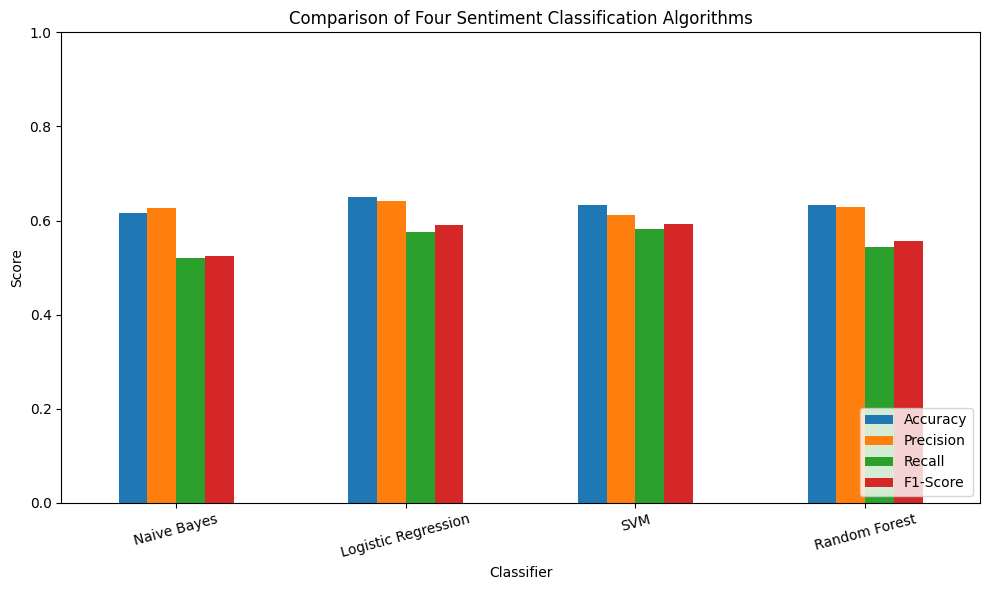

In [ ]:

import matplotlib.pyplot as plt

# Plot the actual evaluation results
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Classifier")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=15
)

plt.title("Comparison of Four Sentiment Classification Algorithms")
plt.ylabel("Score")
plt.xlabel("Classifier")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


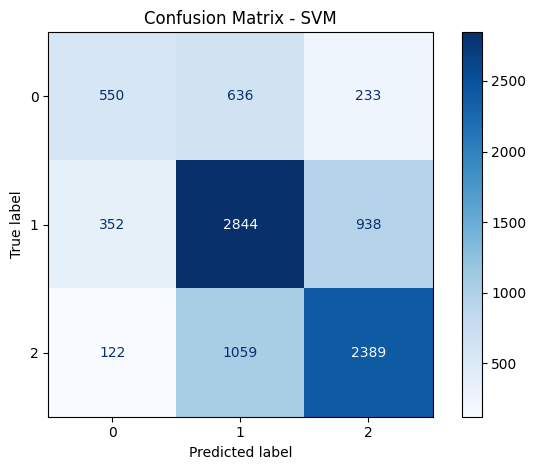

Classifier selected: SVM
Confusion matrix values:
[[ 550  636  233]
 [ 352 2844  938]
 [ 122 1059 2389]]


In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Select the best classifier based on macro F1-score
best_name = results_df.loc[
    results_df["F1-Score"].idxmax(), "Classifier"
]
best_model = trained_models[best_name]

# Predict sentiment for the test reviews
y_pred = best_model.predict(X_test_tfidf)

# Create and display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

display_matrix.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

print("Classifier selected:", best_name)
print("Confusion matrix values:")
print(cm)


What-if experiment results:


,Training data (%),Accuracy,Macro F1-score
0,25,0.6171,0.5284
1,50,0.6326,0.5646
2,100,0.6490,0.5910


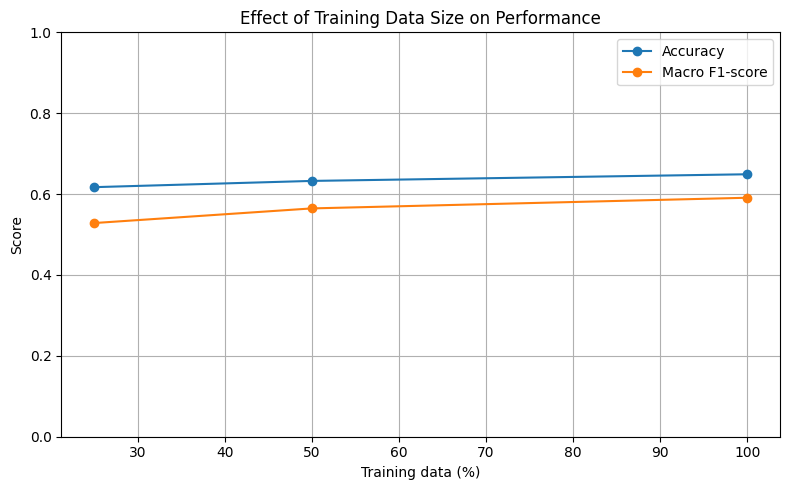

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt

sample_sizes = [0.25, 0.50, 1.00]
what_if_results = []

for fraction in sample_sizes:
    if fraction < 1.0:
        X_subset, _, y_subset, _ = train_test_split(
            X_train_tfidf,
            y_train,
            train_size=fraction,
            random_state=42,
            stratify=y_train
        )
    else:
        X_subset = X_train_tfidf
        y_subset = y_train

    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(X_subset, y_subset)

    predictions = model.predict(X_test_tfidf)

    what_if_results.append({
        "Training data (%)": int(fraction * 100),
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1-score": f1_score(
            y_test, predictions, average="macro"
        )
    })

what_if_df = pd.DataFrame(what_if_results)

print("What-if experiment results:")
display(what_if_df.round(4))

what_if_df.plot(
    x="Training data (%)",
    y=["Accuracy", "Macro F1-score"],
    marker="o",
    figsize=(8, 5)
)

plt.title("Effect of Training Data Size on Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()




In [ ]:

import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/himanshupoddar/AI-ML-Projects/master/Womens%20Clothing%20E-Commerce%20Reviews.csv"

try:
    product_df = pd.read_csv(DATA_URL)
    print("Product-review dataset loaded!")
    print("Dataset shape:", product_df.shape)
    print("Columns:")
    print(product_df.columns.tolist())
    display(product_df.head())
except Exception as e:
    print("Dataset could not be loaded.")
    print("Error:", e)


Dataset could not be loaded.
Error: HTTP Error 404: Not Found


In [ ]:

import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/himanshupoddar/AI-ML-Projects/master/Womens%20Clothing%20E-Commerce%20Reviews.csv"

try:
    product_df = pd.read_csv(DATA_URL)
    print("Product-review dataset loaded!")
    print("Dataset shape:", product_df.shape)
    print("Column names:")
    print(product_df.columns.tolist())
    display(product_df.head())
except Exception as e:
    print("Dataset could not be loaded.")
    print("Error:", e)


Dataset could not be loaded.
Error: HTTP Error 404: Not Found


In [ ]:

import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/nethajinirmal13/Training-datasets/main/Womens%20Clothing%20E-Commerce%20Reviews.csv"

product_df = pd.read_csv(DATA_URL)

print("Product-review dataset loaded successfully!")
print("Dataset size:", product_df.shape)
print("\nColumn names:")
print(product_df.columns.tolist())

display(product_df.head())


Product-review dataset loaded successfully!
Dataset size: (23486, 11)

Column names:
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [ ]:

# Remove rows that have no review text or rating
product_df.columns = product_df.columns.str.strip()
product_df = product_df.dropna(subset=["Review Text", "Rating"]).copy()

# Convert star ratings into three sentiment classes
def get_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

product_df["sentiment"] = product_df["Rating"].apply(get_sentiment)

# Display the number of reviews in each class
print("Sentiment labels created successfully!")
print("\nNumber of reviews in each class:")
print(product_df["sentiment"].value_counts())

# Display sample reviews with their labels
display(product_df[["Review Text", "Rating", "sentiment"]].head())


Sentiment labels created successfully!

Number of reviews in each class:
sentiment
Positive    17448
Neutral      2823
Negative     2370
Name: count, dtype: int64


,Review Text,Rating,sentiment
0,Absolutely wonderful - silky and sexy and comf...,4,Positive
1,Love this dress! it's sooo pretty. i happene...,5,Positive
2,I had such high hopes for this dress and reall...,3,Neutral
3,"I love, love, love this jumpsuit. it's fun, fl...",5,Positive
4,This shirt is very flattering to all due to th...,5,Positive


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Prepare review text and sentiment labels
X = product_df["Review Text"].astype(str)
y = product_df["sentiment"]

# Split data: 80% for training and 20% for testing
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert text into numerical TF-IDF features
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Data preparation completed!")
print("Training reviews:", X_train.shape[0])
print("Testing reviews:", X_test.shape[0])
print("Number of TF-IDF features:", X_train.shape[1])


Data preparation completed!
Training reviews: 18112
Testing reviews: 4529
Number of TF-IDF features: 10000


In [ ]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import time

# Create the four classifiers
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

# Train and evaluate each classifier
for name, model in models.items():
    print("Training:", name)
    start_time = time.time()

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    elapsed_time = time.time() - start_time

    results.append({
        "Classifier": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Time (seconds)": round(elapsed_time, 2)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)
print("\nModel evaluation results:")
display(results_df.round(4))


Training: Naive Bayes
Training: Logistic Regression
Training: Linear SVM
Training: Random Forest

Model evaluation results:


,Classifier,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Time (seconds)
0,Naive Bayes,0.7845,0.6374,0.3805,0.3794,0.05
1,Logistic Regression,0.8229,0.6469,0.5348,0.5682,2.20
2,Linear SVM,0.8143,0.6079,0.5560,0.5753,0.50
3,Random Forest,0.7918,0.6056,0.4108,0.4217,28.21


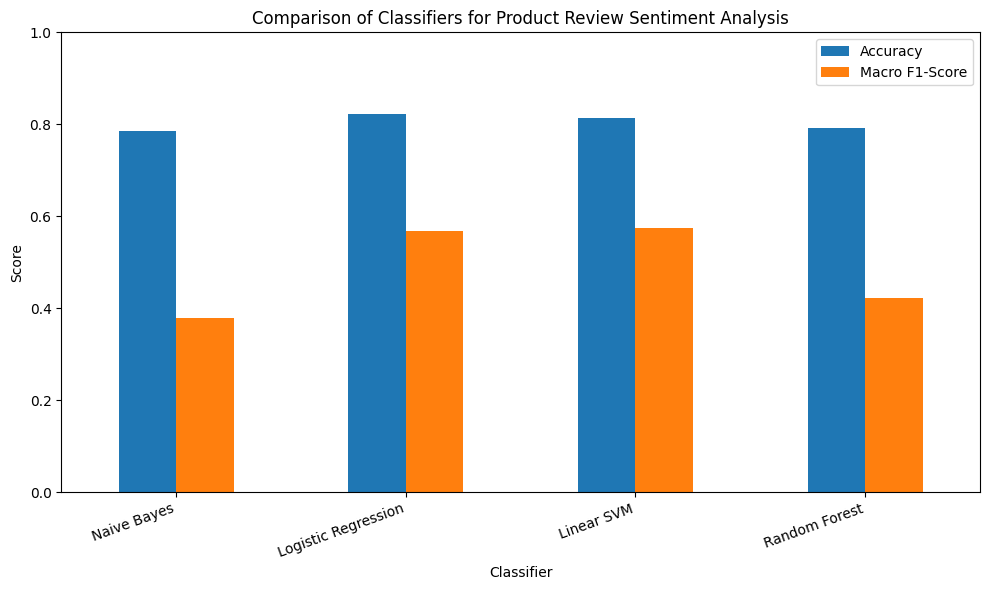

In [ ]:

import matplotlib.pyplot as plt

# Compare the accuracy and macro F1-score of all classifiers
results_plot = results_df.set_index("Classifier")[
    ["Accuracy", "F1-Score (Macro)"]
]

results_plot.plot(kind="bar", figsize=(10, 6))

plt.title("Comparison of Classifiers for Product Review Sentiment Analysis")
plt.ylabel("Score")
plt.xlabel("Classifier")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(["Accuracy", "Macro F1-Score"])
plt.tight_layout()
plt.show()


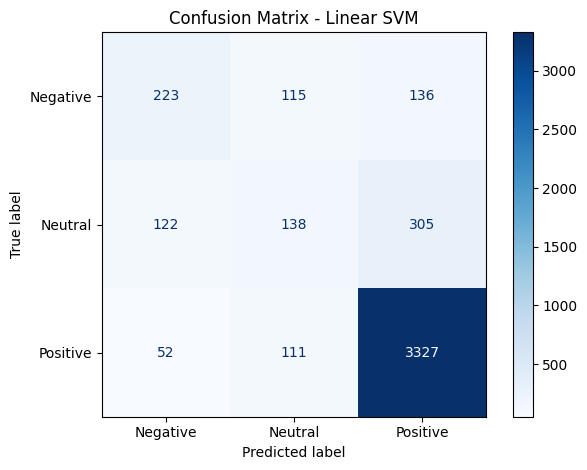

Best model by macro F1-score: Linear SVM


In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Select the model with the highest macro F1-score
best_model_name = results_df.loc[
    results_df["F1-Score (Macro)"].idxmax(), "Classifier"
]
best_model = trained_models[best_model_name]

# Predict sentiment for the test reviews
y_pred = best_model.predict(X_test)

# Create and display the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display_matrix.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

print("Best model by macro F1-score:", best_model_name)


What-if experiment results:


,Training Data (%),Training Reviews,Accuracy,Macro F1-Score,Training and Prediction Time (seconds)
0,25,4528,0.8068,0.5358,0.09
1,50,9056,0.8079,0.5482,0.19
2,100,18112,0.8143,0.5753,1.97


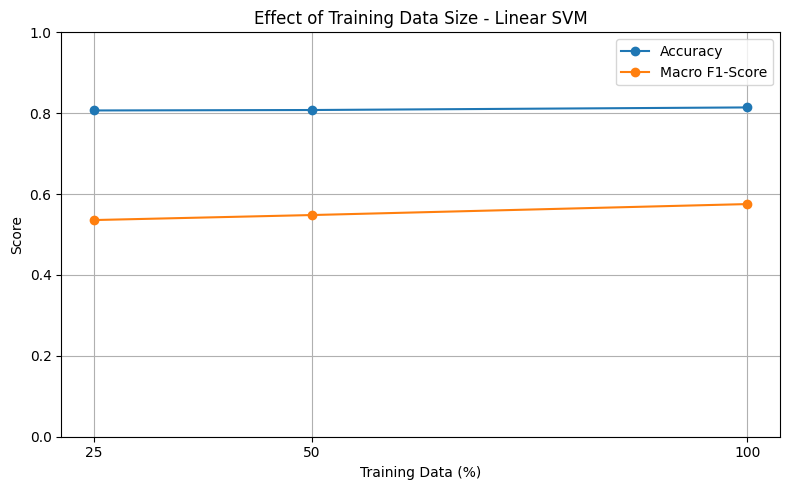

In [ ]:

from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt
import time

# Use the best classifier selected in the previous step
what_if_results = []

for fraction in [0.25, 0.50, 1.00]:
    if fraction < 1.0:
        X_part, _, y_part, _ = train_test_split(
            X_train,
            y_train,
            train_size=fraction,
            random_state=42,
            stratify=y_train
        )
    else:
        X_part, y_part = X_train, y_train

    experiment_model = clone(best_model)

    start = time.time()
    experiment_model.fit(X_part, y_part)
    predictions = experiment_model.predict(X_test)
    elapsed = time.time() - start

    what_if_results.append({
        "Training Data (%)": int(fraction * 100),
        "Training Reviews": X_part.shape[0],
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1-Score": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Training and Prediction Time (seconds)": round(elapsed, 2)
    })

what_if_df = pd.DataFrame(what_if_results)

print("What-if experiment results:")
display(what_if_df.round(4))

what_if_df.plot(
    x="Training Data (%)",
    y=["Accuracy", "Macro F1-Score"],
    marker="o",
    figsize=(8, 5)
)

plt.title(f"Effect of Training Data Size - {best_model_name}")
plt.xlabel("Training Data (%)")
plt.ylabel("Score")
plt.xticks([25, 50, 100])
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# Save the main classifier comparison results
results_df.to_csv("classifier_results.csv", index=False)

# Save the what-if experiment results
what_if_df.to_csv("what_if_results.csv", index=False)

print("Results saved successfully!")
print("Files created:")
print("1. classifier_results.csv")
print("2. what_if_results.csv")

print("\nClassifier results:")
display(results_df.round(4))

print("\nWhat-if experiment results:")
display(what_if_df.round(4))


Results saved successfully!
Files created:
1. classifier_results.csv
2. what_if_results.csv

Classifier results:


,Classifier,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Time (seconds)
0,Naive Bayes,0.7845,0.6374,0.3805,0.3794,0.05
1,Logistic Regression,0.8229,0.6469,0.5348,0.5682,2.20
2,Linear SVM,0.8143,0.6079,0.5560,0.5753,0.50
3,Random Forest,0.7918,0.6056,0.4108,0.4217,28.21



What-if experiment results:


,Training Data (%),Training Reviews,Accuracy,Macro F1-Score,Training and Prediction Time (seconds)
0,25,4528,0.8068,0.5358,0.09
1,50,9056,0.8079,0.5482,0.19
2,100,18112,0.8143,0.5753,1.97


In [ ]:
DATA_URL = "https://huggingface.co/datasets/Censius-AI/ECommerce-Women-Clothing-Reviews/resolve/main/Womens%20Clothing%20E-Commerce%20Reviews.csv"

df = pd.read_csv(DATA_URL)
print("Original shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Original shape: (23486, 11)
Columns: ['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


## 3. Prepare labels and inspect the data

We use the review text as the input and the rating-derived sentiment as the target. Missing review text or ratings are removed. This is a three-class classification task.

In [ ]:
# Column names in the source dataset include 'Review Text' and 'Rating'.
df = df[["Review Text", "Rating"]].copy()
df = df.dropna(subset=["Review Text", "Rating"])
df["Review Text"] = df["Review Text"].astype(str).str.strip()
df = df[df["Review Text"].str.len() > 0]
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
df = df.dropna(subset=["Rating"])
df["Rating"] = df["Rating"].astype(int)

def rating_to_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    return "Positive"

df["Sentiment"] = df["Rating"].apply(rating_to_sentiment)
df = df[["Review Text", "Sentiment"]].drop_duplicates().reset_index(drop=True)

print("Cleaned shape:", df.shape)
display(df.head())
print("\nClass counts:")
display(df["Sentiment"].value_counts().rename_axis("Sentiment").to_frame("Count"))

Cleaned shape: (22634, 2)


,Review Text,Sentiment
0,Absolutely wonderful - silky and sexy and comf...,Positive
1,Love this dress! it's sooo pretty. i happene...,Positive
2,I had such high hopes for this dress and reall...,Neutral
3,"I love, love, love this jumpsuit. it's fun, fl...",Positive
4,This shirt is very flattering to all due to th...,Positive



Class counts:


,Count
Sentiment,
Positive,17442
Neutral,2823
Negative,2369


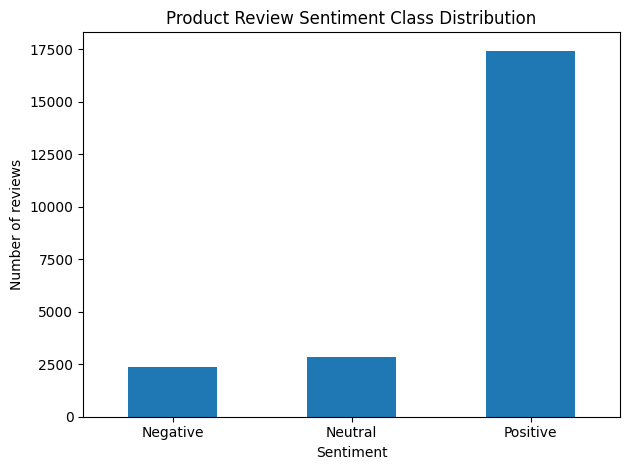

In [ ]:
# Visualize class distribution. This chart is generated from the loaded data.
class_counts = df["Sentiment"].value_counts().reindex(["Negative", "Neutral", "Positive"])
ax = class_counts.plot(kind="bar", rot=0)
ax.set_title("Product Review Sentiment Class Distribution")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()

## 4. Preprocess the text

The preprocessing function lowercases text, tokenizes words, removes common English stop words, and applies Porter stemming. Negation words such as **not**, **no**, **nor**, and **never** are deliberately retained because they can reverse sentiment (for example, “not good”).

The TF-IDF vectorizer then creates numeric features from the processed text.

In [ ]:
import nltk
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()
negations = {"no", "not", "nor", "never"}
stop_words = set(ENGLISH_STOP_WORDS) - negations

def preprocess_text(text):
    tokens = re.findall(r"[a-zA-Z]+", str(text).lower())
    tokens = [stemmer.stem(tok) for tok in tokens if tok not in stop_words]
    return " ".join(tokens)

# Show one example before and after preprocessing.
example_text = df.loc[0, "Review Text"]
print("BEFORE:", example_text)
print("\nAFTER: ", preprocess_text(example_text))

BEFORE: Absolutely wonderful - silky and sexy and comfortable

AFTER:  absolut wonder silki sexi comfort


## 5. Create a manageable, stratified sample and split the data

KNN can be computationally expensive on sparse text data. To keep this notebook practical in a free Colab session, we use up to 12,000 reviews, sampled with the original class proportions. This is still far above the assignment minimum and gives all four models the same training and test examples. The sample size and split are printed below so they can be reported accurately.

In [ ]:
MAX_SAMPLES = 12000
if len(df) > MAX_SAMPLES:
    df_model, _ = train_test_split(
        df,
        train_size=MAX_SAMPLES,
        random_state=RANDOM_STATE,
        stratify=df["Sentiment"]
    )
    df_model = df_model.reset_index(drop=True)
else:
    df_model = df.copy().reset_index(drop=True)

print("Rows used for modelling:", len(df_model))
print("Class distribution in modelling data:")
display(df_model["Sentiment"].value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    df_model["Review Text"],
    df_model["Sentiment"],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df_model["Sentiment"]
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Rows used for modelling: 12000
Class distribution in modelling data:


,count
Sentiment,
Positive,9247
Neutral,1497
Negative,1256


Training rows: 9600
Testing rows: 2400


## 6. Transform reviews using TF-IDF

TF-IDF gives more weight to terms that are informative for a review and less weight to terms that occur in many reviews. We fit the vectorizer on training text only, then transform the test text to avoid data leakage.

In [ ]:
MAX_FEATURES = 5000

vectorizer = TfidfVectorizer(
    preprocessor=preprocess_text,
    lowercase=False,        # preprocessing already lowercases
    tokenizer=str.split,    # preprocessing returns space-separated stems
    token_pattern=None,
    ngram_range=(1, 2),
    max_features=MAX_FEATURES,
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF training matrix shape:", X_train_tfidf.shape)
print("TF-IDF testing matrix shape:", X_test_tfidf.shape)
print("Number of vocabulary terms:", len(vectorizer.vocabulary_))
print("Sample vocabulary terms:", list(vectorizer.vocabulary_.keys())[:25])

TF-IDF training matrix shape: (9600, 5000)
TF-IDF testing matrix shape: (2400, 5000)
Number of vocabulary terms: 5000
Sample vocabulary terms: ['absolut', 'love', 'look', 'shirt', 'built', 'layer', 'piec', 'overal', 'garment', 'lightweight', 'not', 'heavi', 'ad', 'run', 'realli', 'larg', 'gener', 'brand', 'say', 'use', 'stick', 'normal', 'size', 'compar', 'think']


## 7. Train the four required classifiers

All four models use the same TF-IDF training matrix and are evaluated on the same held-out test set. We use macro-averaged precision, recall, and F1-score so each sentiment class contributes equally to these metrics.

In [ ]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=80, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5, weights="distance", metric="cosine", algorithm="brute"),
    "SVM": LinearSVC(class_weight="balanced", random_state=RANDOM_STATE),
    "Naive Bayes": MultinomialNB(alpha=0.5)
}

results = []
predictions = {}

for name, model in models.items():
    print(f"Training/evaluating: {name}")
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score (macro)", ascending=False).reset_index(drop=True)
display(results_df.round(4))

Training/evaluating: Decision Tree
Training/evaluating: KNN
Training/evaluating: SVM
Training/evaluating: Naive Bayes


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,SVM,0.8008,0.5853,0.5870,0.5861
1,KNN,0.7808,0.5396,0.4534,0.4744
2,Decision Tree,0.6846,0.4509,0.4757,0.4588
3,Naive Bayes,0.7933,0.6113,0.4180,0.4354


## 8. Compare model performance with a graph

The graph below is generated from your run's actual scores. Do not write numerical results in your report until you have executed the notebook.

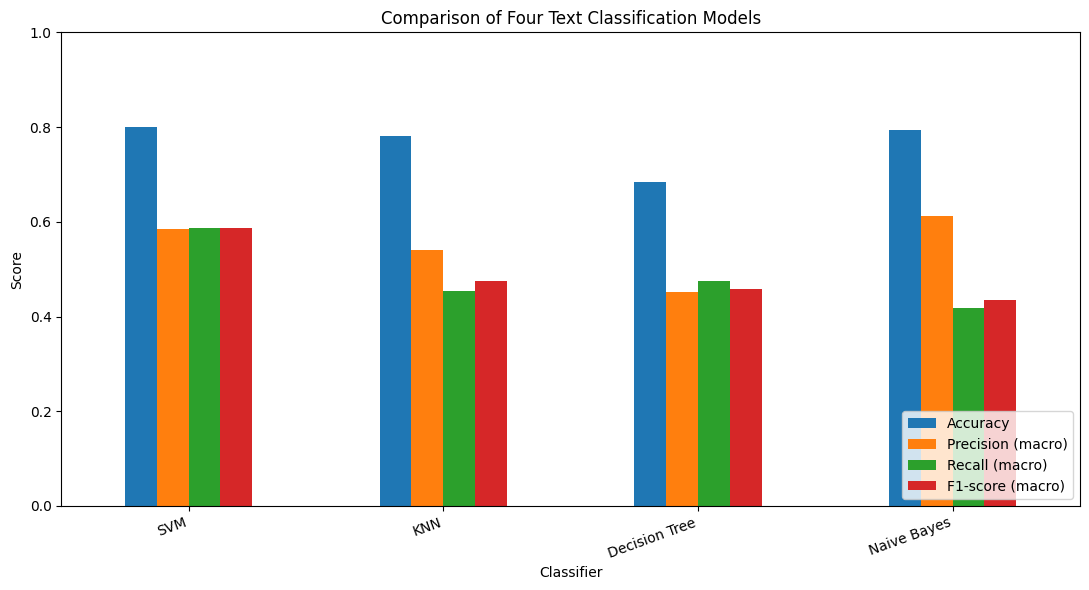

In [ ]:
metric_columns = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
ax = results_df.set_index("Model")[metric_columns].plot(kind="bar", figsize=(11, 6))
ax.set_title("Comparison of Four Text Classification Models")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xlabel("Classifier")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9. Classification report and confusion matrix

A confusion matrix shows the actual class versus the predicted class. The rows are actual labels and columns are predicted labels. We display the matrix for the model with the highest macro F1-score in this run.

Best model by macro F1-score: SVM

Classification report:
              precision    recall  f1-score   support

    Negative       0.48      0.50      0.49       251
     Neutral       0.36      0.35      0.35       299
    Positive       0.92      0.92      0.92      1850

    accuracy                           0.80      2400
   macro avg       0.59      0.59      0.59      2400
weighted avg       0.80      0.80      0.80      2400



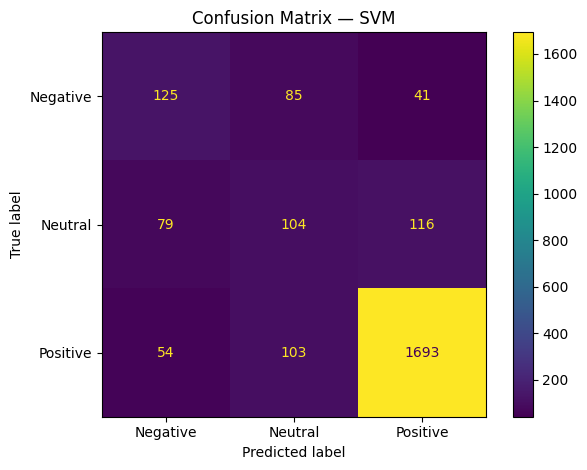

In [ ]:
best_model_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]
labels = ["Negative", "Neutral", "Positive"]

print("Best model by macro F1-score:", best_model_name)
print("\nClassification report:")
print(classification_report(y_test, best_predictions, labels=labels, zero_division=0))

cm = confusion_matrix(y_test, best_predictions, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## 10. What-if experiment: change K in KNN

The assignment requires at least one what-if experiment. Here we change K from 3 to 5 to 7 and compare macro F1-score. The TF-IDF representation and train/test split stay the same, so the comparison isolates the effect of this KNN parameter.

,K,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,3,0.7683,0.5173,0.4667,0.4817
1,5,0.7808,0.5396,0.4534,0.4744
2,7,0.7925,0.5808,0.4510,0.4766


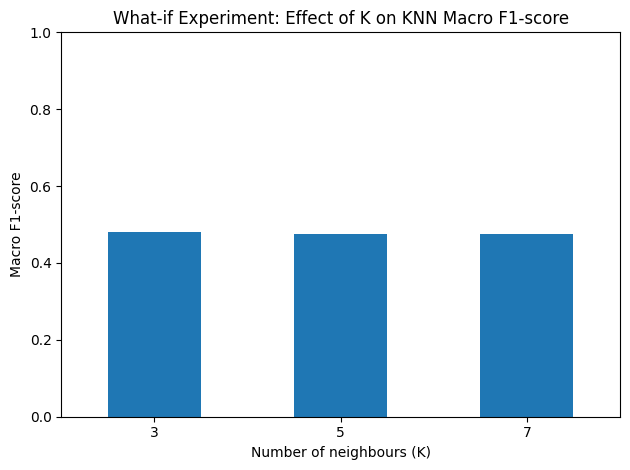

In [ ]:
knn_results = []
for k in [3, 5, 7]:
    knn = KNeighborsClassifier(n_neighbors=k, weights="distance", metric="cosine", algorithm="brute")
    knn.fit(X_train_tfidf, y_train)
    pred = knn.predict(X_test_tfidf)
    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, pred, average="macro", zero_division=0)
    })

knn_results_df = pd.DataFrame(knn_results)
display(knn_results_df.round(4))

ax = knn_results_df.set_index("K")["F1-score (macro)"].plot(kind="bar", rot=0)
ax.set_title("What-if Experiment: Effect of K on KNN Macro F1-score")
ax.set_xlabel("Number of neighbours (K)")
ax.set_ylabel("Macro F1-score")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 11. Try predictions on new reviews

Use this function to test the trained best model on new example text. These are demonstrations, not part of the held-out test metrics.

In [ ]:
best_model = models[best_model_name]

def predict_sentiment(review_text):
    review_vector = vectorizer.transform([review_text])
    prediction = best_model.predict(review_vector)[0]
    return prediction

test_reviews = [
    "The fabric is comfortable and the quality is excellent.",
    "The product was damaged and I am very disappointed.",
    "The item arrived yesterday and looks like the picture."
]

for review in test_reviews:
    print(f"Review: {review}\nPredicted sentiment: {predict_sentiment(review)}\n")

Review: The fabric is comfortable and the quality is excellent.
Predicted sentiment: Positive

Review: The product was damaged and I am very disappointed.
Predicted sentiment: Negative

Review: The item arrived yesterday and looks like the picture.
Predicted sentiment: Neutral



## 12. Export results for your report and GitHub

This saves the model comparison, KNN what-if results, and test predictions as CSV files. You can download these from the Colab file panel or commit them to your project repository.

In [ ]:
results_df.to_csv("model_comparison_results.csv", index=False)
knn_results_df.to_csv("knn_what_if_results.csv", index=False)

prediction_output = pd.DataFrame({
    "Review": X_test.reset_index(drop=True),
    "Actual Sentiment": y_test.reset_index(drop=True),
    "Predicted Sentiment (Best Model)": pd.Series(best_predictions).reset_index(drop=True)
})
prediction_output.to_csv("test_predictions.csv", index=False)

print("Saved: model_comparison_results.csv")
print("Saved: knn_what_if_results.csv")
print("Saved: test_predictions.csv")

Saved: model_comparison_results.csv
Saved: knn_what_if_results.csv
Saved: test_predictions.csv


## 13. Report-writing template

Complete this section after running the notebook. Replace every bracketed item with values from your actual output.

### Title
Product Review Sentiment Analysis Using Machine Learning

### Problem statement
Online stores receive many customer reviews, and manually reading each review to understand customer satisfaction can be time-consuming. This project develops a text classification system that labels product reviews as Negative, Neutral, or Positive and compares four machine-learning classifiers.

### Dataset
The dataset contains e-commerce clothing reviews and star ratings. The target sentiment is derived using the following rule: ratings 1–2 are Negative, rating 3 is Neutral, and ratings 4–5 are Positive. After removing missing or empty reviews and duplicate review texts, the final dataset contains **[fill in rows]** reviews. The class counts are **[fill in counts from output]**.

### Methodology
The review text is lowercased, tokenized, stripped of common stop words while retaining negation words, and stemmed using the Porter stemmer. TF-IDF with unigrams and bigrams is used to represent the text numerically. The data is split into 80% training and 20% testing using stratification. Decision Tree, KNN, SVM, and Naïve Bayes are trained and evaluated on the same split.

### Evaluation
Report accuracy, macro precision, macro recall, and macro F1-score for all four classifiers in a table. Insert the model-comparison graph and the best model's confusion matrix.

### What-if experiment
The value of K in KNN is changed to 3, 5, and 7 while keeping the data split and TF-IDF features unchanged. Compare the resulting scores and explain how changing K affected the classification performance.

### Conclusion
The best model in this experiment was **[model name]**, based on **[metric used, e.g. macro F1-score]**. Its measured score was **[actual score]**. The results show **[your observation from the confusion matrix and metrics]**. One limitation is that the sentiment labels are inferred from star ratings, which may not perfectly match the sentiment expressed in every review.

### Reference
Censius-AI. *ECommerce-Women-Clothing-Reviews* dataset. https://huggingface.co/datasets/Censius-AI/ECommerce-Women-Clothing-Reviews

## 14. GitHub submission checklist

- [ ] Save this notebook as `Product_Review_Sentiment_Analysis.ipynb`.
- [ ] Run every cell and check for errors.
- [ ] Ensure report metrics match the output generated by your run.
- [ ] Include the dataset citation and a README explaining the project and how to run it.
- [ ] Include the exported CSV results if your instructor requests them. Avoid committing large or unnecessary raw datasets if linking to the public source is sufficient.
- [ ] Make at least three meaningful commits, as required by your course instructions if applicable to your submission.
- [ ] Submit the GitHub repository and assignment through Google Classroom.
- [ ] Be ready to explain TF-IDF, the four classifiers, evaluation metrics, confusion matrix, and the KNN what-if experiment during viva.